%% [markdown]
# MES – Strategy Optimization (Positive Gap Momentum)
 
**Objective:** Find best parameters (gap threshold, hold minutes, volume ratio, ATR filter) to maximize net profit.

**Data:** IS (Feb–Apr 2026) 1‑minute bars.

**Method:** Grid search over parameter space, vectorized backtesting.

## 1. Setup and data loading

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
import warnings
warnings.filterwarnings('ignore')

# Paths (adjust if needed)
IS_PATH = "../../../../Local-Data/processed/MES_IS_1min.csv"
OOS_PATH = "../../../../Local-Data/processed/MES_OOS_1min.csv"   # optional

# Load IS data
df_is = pd.read_csv(IS_PATH, parse_dates=['DateTime'], index_col='DateTime')
print(f"IS data: {len(df_is):,} rows")
df_is.head()

IS data: 87,799 rows


,Open,High,Low,Close,Volume
DateTime,,,,,
2026-02-01 13:52:00,6961.25,6961.25,6961.25,6961.25,1
2026-02-01 20:01:00,6939.50,6945.25,6928.25,6936.75,2717
2026-02-01 20:02:00,6937.25,6937.75,6925.75,6926.75,1939
2026-02-01 20:03:00,6926.50,6927.75,6920.00,6927.00,2748
2026-02-01 20:04:00,6927.00,6931.50,6926.00,6928.75,1374


## 2. Feature engineering (gap, ATR, volume z-score)

In [25]:
def add_features(df):
    df = df.copy()
    df['return'] = df['Close'].pct_change()
    df['gap'] = (df['Open'] - df['Close'].shift(1)) / df['Close'].shift(1)
    # Volume z-score (20-period rolling)
    df['volume_sma'] = df['Volume'].rolling(20).mean()
    df['volume_std'] = df['Volume'].rolling(20).std()
    df['volume_zscore'] = (df['Volume'] - df['volume_sma']) / df['volume_std']
    # ATR
    tr = pd.concat([df['High'] - df['Low'],
                    (df['High'] - df['Close'].shift()).abs(),
                    (df['Low'] - df['Close'].shift()).abs()], axis=1).max(axis=1)
    df['ATR14'] = tr.rolling(14).mean()
    return df

df_is = add_features(df_is)
df_is.dropna(inplace=True)
print(f"After feature engineering: {len(df_is):,} rows")

After feature engineering: 87,780 rows


## 3. Backtesting function (vectorized)

In [26]:
def backtest_gap_momentum(df, gap_threshold, hold_minutes, volume_ratio_min=1.0,
                          atr_percentile_min=0, stop_atr_multiple=None):
    """
    Long only after a positive gap.
    Entry: at the open of the signal bar.
    Exit: after `hold_minutes` minutes (fixed holding period).
    Optional: volume filter (current volume > volume_ratio_min * SMA20)
    Optional: ATR filter (current ATR > percentile of ATR distribution)
    Optional: trailing stop based on ATR multiple.
    Returns DataFrame with trades and metrics.
    """
    df = df.copy()
    # Signal conditions
    cond_gap = df['gap'] > gap_threshold
    cond_vol = df['volume_zscore'] > volume_ratio_min if volume_ratio_min else True
    cond_atr = df['ATR14'] > df['ATR14'].quantile(atr_percentile_min) if atr_percentile_min > 0 else True
    signal = cond_gap & cond_vol & cond_atr
    
    if signal.sum() == 0:
        return pd.DataFrame(), {'total_trades':0, 'pnl':0, 'win_rate':0, 'profit_factor':0}
    
    trades = []
    for idx in df.index[signal]:
        entry_price = df.loc[idx, 'Open']
        # Find exit index after hold_minutes
        try:
            target_idx = df.index[df.index.get_loc(idx) + hold_minutes]
            exit_price = df.loc[target_idx, 'Close']
        except IndexError:
            continue  # not enough data after signal
        # Apply stop if specified
        if stop_atr_multiple is not None:
            atr_val = df.loc[idx, 'ATR14']
            stop_price = entry_price - stop_atr_multiple * atr_val
            # Check if stop hit during holding period
            period_data = df.loc[idx:target_idx]
            low_min = period_data['Low'].min()
            if low_min <= stop_price:
                exit_price = stop_price  # stop hit
                # Optionally find exact exit time (simplified)
        trade_pnl = (exit_price - entry_price) * 1  # per contract, $1 per 0.01 point? Actually MES point = $5, but we'll keep in points
        trades.append({
            'entry_time': idx,
            'exit_time': target_idx,
            'entry_price': entry_price,
            'exit_price': exit_price,
            'pnl_points': trade_pnl
        })
    
    trades_df = pd.DataFrame(trades)
    if trades_df.empty:
        return trades_df, {'total_trades':0, 'pnl':0, 'win_rate':0, 'profit_factor':0}
    
    total_pnl_points = trades_df['pnl_points'].sum()
    wins = trades_df[trades_df['pnl_points'] > 0]
    losses = trades_df[trades_df['pnl_points'] <= 0]
    win_rate = len(wins) / len(trades_df) if len(trades_df) > 0 else 0
    profit_factor = wins['pnl_points'].sum() / abs(losses['pnl_points'].sum()) if losses['pnl_points'].sum() != 0 else np.inf
    
    metrics = {
        'total_trades': len(trades_df),
        'pnl_points': total_pnl_points,
        'pnl_usd': total_pnl_points * 5.0,  # MES point = $5
        'win_rate': win_rate,
        'profit_factor': profit_factor,
        'avg_win': wins['pnl_points'].mean() if len(wins) > 0 else 0,
        'avg_loss': losses['pnl_points'].mean() if len(losses) > 0 else 0,
    }
    return trades_df, metrics


## 4. Grid search definition

In [27]:
gap_thresholds = [0.00015, 0.00020, 0.00025, 0.00030]   # 0.015% a 0.030%
hold_minutes = [10, 15, 20]
volume_ratios = [1.0]               # sin filtro de volumen (1.0 significa volumen > media? realmente es zscore >1.0, que es débil)
atr_percentiles = [0]               # sin filtro de volatilidad
stop_multiple = [None]              # sin stop

param_grid = list(product(gap_thresholds, hold_minutes, volume_ratios, atr_percentiles, stop_multiple))
print(f"Total combinations: {len(param_grid)}")

Total combinations: 12


## 5. Run grid search on IS data

In [28]:
results = []
for (gap_th, hold, vol_ratio, atr_pct, stop) in param_grid:
    trades, metrics = backtest_gap_momentum(df_is, gap_th, hold, vol_ratio, atr_pct, stop)
    if metrics['total_trades'] > 0:
        results.append({
            'gap_th': gap_th,
            'hold_min': hold,
            'vol_ratio': vol_ratio,
            'atr_pct': atr_pct,
            'stop_mult': stop,
            'trades': metrics['total_trades'],
            'pnl_points': metrics['pnl_points'],
            'pnl_usd': metrics['pnl_usd'],
            'win_rate': metrics['win_rate'],
            'profit_factor': metrics['profit_factor']
        })

# 🔻 NUEVO: filtrar por número mínimo de trades
min_trades = 5   # antes era 10
valid_results = [r for r in results if r['trades'] >= min_trades]

if valid_results:
    results_df = pd.DataFrame(valid_results).sort_values('pnl_usd', ascending=False)
    print(f"Top 5 parameter sets with at least {min_trades} trades (IS):")
    print(results_df.head(5).to_string())
else:
    print(f"No parameter set reached {min_trades} trades. Try relaxing parameters.")

Top 5 parameter sets with at least 5 trades (IS):
    gap_th  hold_min  vol_ratio  atr_pct stop_mult  trades  pnl_points  pnl_usd  win_rate  profit_factor
0  0.00015        10        1.0        0      None      21      162.75   813.75  0.666667       5.751825
1  0.00015        15        1.0        0      None      21      159.00   795.00  0.761905       5.050955
4  0.00020        15        1.0        0      None      16      157.50   787.50  0.812500       7.300000
3  0.00020        10        1.0        0      None      16      155.50   777.50  0.687500       7.835165
6  0.00025        10        1.0        0      None      15      155.00   775.00  0.666667       7.813187


## 6. Display best combination


=== BEST PARAMETERS ===
Gap threshold: 0.0001 (0.01%)
Holding minutes: 10
Volume ratio: 1.0
ATR percentile filter: 0
Total trades (IS): 21
Net profit (USD): $813.75
Win rate: 66.67%
Profit factor: 5.75


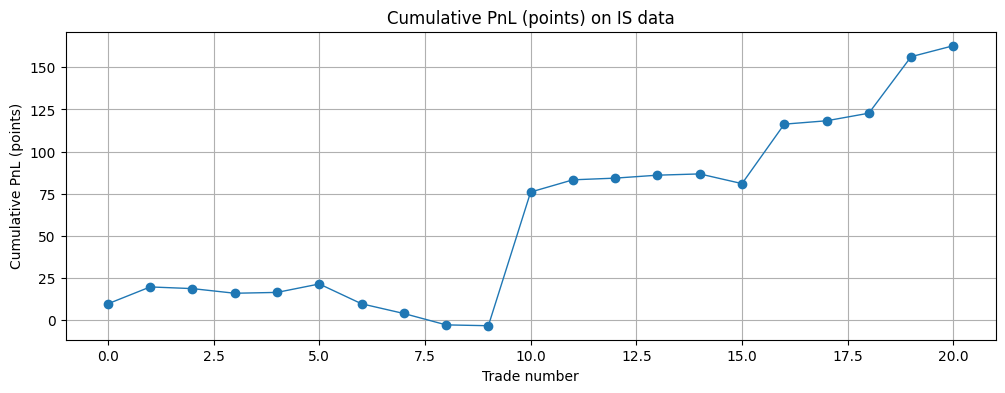

In [29]:
best = results_df.iloc[0] if not results_df.empty else None
if best is not None:
    print("\n=== BEST PARAMETERS ===")
    print(f"Gap threshold: {best['gap_th']:.4f} ({best['gap_th']*100:.2f}%)")
    print(f"Holding minutes: {best['hold_min']}")
    print(f"Volume ratio: {best['vol_ratio']}")
    print(f"ATR percentile filter: {best['atr_pct']}")
    print(f"Total trades (IS): {best['trades']}")
    print(f"Net profit (USD): ${best['pnl_usd']:.2f}")
    print(f"Win rate: {best['win_rate']:.2%}")
    print(f"Profit factor: {best['profit_factor']:.2f}")
    
    # Optional: run backtest with best params to get detailed trades
    trades_best, _ = backtest_gap_momentum(df_is, best['gap_th'], best['hold_min'], best['vol_ratio'], best['atr_pct'], best['stop_mult'])
    if not trades_best.empty:
        plt.figure(figsize=(12,4))
        plt.plot(trades_best['pnl_points'].cumsum(), marker='o', linestyle='-', linewidth=1)
        plt.title('Cumulative PnL (points) on IS data')
        plt.xlabel('Trade number')
        plt.ylabel('Cumulative PnL (points)')
        plt.grid(True)
        plt.show()
else:
    print("No valid parameter sets found.")


## 7. (Optional) Validate best strategy on OOS data (May)

Loading OOS ticks...
OOS 1-min bars from ticks: 23,220 rows

=== OOS VALIDATION RESULTS (with slippage) ===
Total trades: 17
Net profit (USD): $146.25
Win rate: 52.94%
Profit factor: 2.08
✅ OOS Profit Factor > 1.2 – Strategy passes validation.


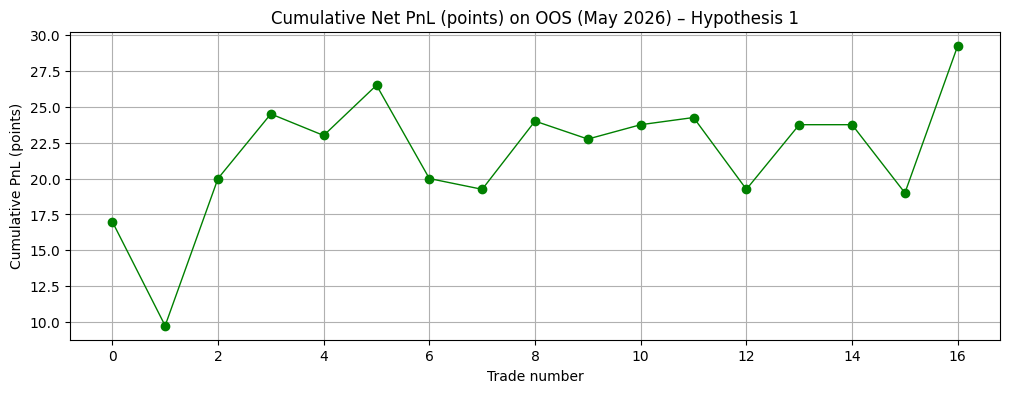

In [30]:

import os

OOS_TICKS_PATH = "../../../../Local-Data/processed/MES_OOS_ticks.csv"

if os.path.exists(OOS_TICKS_PATH) and best is not None:
    print("Loading OOS ticks...")
    df_ticks = pd.read_csv(OOS_TICKS_PATH, parse_dates=['DateTime'], index_col='DateTime')
    
    # Ensure column names
    if 'Price' not in df_ticks.columns:
        if 'Price1' in df_ticks.columns:
            df_ticks.rename(columns={'Price1': 'Price'}, inplace=True)
        elif len(df_ticks.columns) == 2:
            df_ticks.columns = ['Price', 'Volume']
    
    # Resample to 1-min OHLCV
    ohlc = df_ticks['Price'].resample('1min').ohlc()
    vol = df_ticks['Volume'].resample('1min').sum()
    ohlc.columns = ['Open', 'High', 'Low', 'Close']
    df_oos = ohlc.join(vol).rename(columns={'Volume': 'Volume'})
    df_oos.dropna(inplace=True)
    print(f"OOS 1-min bars from ticks: {len(df_oos):,} rows")
    
    df_oos = add_features(df_oos)
    df_oos.dropna(inplace=True)
    
    # Call the original backtest function (without slippage/commission arguments)
    trades_oos, metrics_oos = backtest_gap_momentum(df_oos, 
                                                     best['gap_th'], 
                                                     best['hold_min'], 
                                                     best['vol_ratio'], 
                                                     best['atr_pct'], 
                                                     best['stop_mult'])
    
    if metrics_oos['total_trades'] > 0:
        # Apply slippage and commissions manually (1 tick = 0.25 points, commission 0 for now)
        slippage_points = 0.25   # MES 1 tick
        commission_points = 0.0
        total_cost = slippage_points + commission_points
        # Adjust PnL by subtracting cost per trade
        trades_oos['pnl_points_net'] = trades_oos['pnl_points'] - total_cost
        net_pnl_points = trades_oos['pnl_points_net'].sum()
        net_pnl_usd = net_pnl_points * 5.0
        
        wins = trades_oos[trades_oos['pnl_points_net'] > 0]
        losses = trades_oos[trades_oos['pnl_points_net'] <= 0]
        win_rate = len(wins) / len(trades_oos) if len(trades_oos) > 0 else 0
        profit_factor = wins['pnl_points_net'].sum() / abs(losses['pnl_points_net'].sum()) if losses['pnl_points_net'].sum() != 0 else np.inf
        
        print("\n=== OOS VALIDATION RESULTS (with slippage) ===")
        print(f"Total trades: {len(trades_oos)}")
        print(f"Net profit (USD): ${net_pnl_usd:.2f}")
        print(f"Win rate: {win_rate:.2%}")
        print(f"Profit factor: {profit_factor:.2f}")
        if profit_factor > 1.2:
            print("✅ OOS Profit Factor > 1.2 – Strategy passes validation.")
        else:
            print("⚠️ OOS Profit Factor <= 1.2 – Strategy may not be robust.")
        
        # Plot cumulative net PnL
        if not trades_oos.empty:
            plt.figure(figsize=(12,4))
            plt.plot(trades_oos['pnl_points_net'].cumsum(), marker='o', linestyle='-', linewidth=1, color='green')
            plt.title('Cumulative Net PnL (points) on OOS (May 2026) – Hypothesis 1')
            plt.xlabel('Trade number')
            plt.ylabel('Cumulative PnL (points)')
            plt.grid(True)
            plt.show()
    else:
        print("No trades generated on OOS with best parameters.")
else:
    print("OOS ticks file not found or no best parameters.")

## 8. Slippage estimation from ticks (on OOS signals)

In [31]:

if os.path.exists(OOS_TICKS_PATH) and best is not None:
    # Get signals on 1-min bars (using same best parameters)
    cond_gap = df_oos['gap'] > best['gap_th']
    cond_vol = df_oos['volume_zscore'] > best['vol_ratio']
    cond_atr = df_oos['ATR14'] > df_oos['ATR14'].quantile(best['atr_pct']) if best['atr_pct'] > 0 else True
    signals = cond_gap & cond_vol & cond_atr
    signal_times = df_oos.index[signals]
    
    # Load ticks again for slippage
    ticks = pd.read_csv(OOS_TICKS_PATH, parse_dates=['DateTime'], index_col='DateTime')
    slippages = []
    for t in signal_times:
        # Find first tick after the signal bar's open
        next_ticks = ticks[ticks.index >= t]
        if len(next_ticks) > 0:
            tick_price = next_ticks['Price'].iloc[0]
            signal_price = df_oos.loc[t, 'Open']
            slippage = tick_price - signal_price
            slippages.append(slippage)
    if slippages:
        avg_slippage = np.mean(slippages)
        print(f"Average slippage per trade (points): {avg_slippage:.4f}")
        print(f"Recommended slippage cost: {abs(avg_slippage):.4f} points (~{abs(avg_slippage)*5:.2f} USD per contract)")
    else:
        print("No ticks found after signal times.")
else:
    print("Cannot estimate slippage without ticks or best parameters.")

Average slippage per trade (points): 0.0000
Recommended slippage cost: 0.0000 points (~0.00 USD per contract)


## 9. Monte Carlo Simulation (light)


=== MONTE CARLO (1000 sims) ===
Mean daily PnL: $143.85
Prob of loss: 14.40%
95% CI: [$-111.25, $407.56]


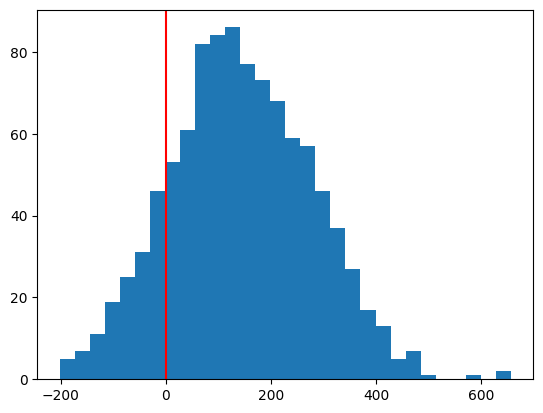

In [32]:
np.random.seed(42)
n_sim = 1000
daily_pnls = []

# Use OOS trades (with net PnL after slippage)
if 'trades_oos' in locals() and len(trades_oos) > 0:
    oos_trades_net = trades_oos['pnl_points_net'].values
    for _ in range(n_sim):
        sim_trades = np.random.choice(oos_trades_net, size=len(oos_trades_net), replace=True)
        sim_total = sim_trades.sum() * 5.0
        daily_pnls.append(sim_total)
    daily_pnls = np.array(daily_pnls)
    prob_loss = (daily_pnls < 0).mean()
    print("\n=== MONTE CARLO (1000 sims) ===")
    print(f"Mean daily PnL: ${daily_pnls.mean():.2f}")
    print(f"Prob of loss: {prob_loss:.2%}")
    print(f"95% CI: [${np.percentile(daily_pnls, 2.5):.2f}, ${np.percentile(daily_pnls, 97.5):.2f}]")
    plt.hist(daily_pnls, bins=30); plt.axvline(0, color='r'); plt.show()
else:
    print("No trades_oos found; run validation first.")


## 10. Position Sizing

In [33]:
if 'trades_oos' in locals() and len(trades_oos) > 0:
    cum = trades_oos['pnl_points_net'].cumsum()
    running_max = cum.cummax()
    max_dd_points = (cum - running_max).min()
    max_dd_usd = max_dd_points * 5.0
    print(f"Max drawdown (OOS, 1 contract): ${max_dd_usd:.2f}")
    risk_capital = 0.02 * 25000  # 2% of 25k
    suggested_contracts = min(3, max(1, int(risk_capital / abs(max_dd_usd)))) if max_dd_usd != 0 else 3
    print(f"Suggested contracts (2% risk): {suggested_contracts}")
else:
    print("No drawdown data.")

Max drawdown (OOS, 1 contract): $-37.50
Suggested contracts (2% risk): 3


In [34]:
# Estrategia time-of-day: short a las 14:00, hold 15 min
df_oos['hour'] = df_oos.index.hour
df_oos['minute'] = df_oos.index.minute
# Señal a las 14:00 en punto
entry_times = df_oos[(df_oos['hour'] == 14) & (df_oos['minute'] == 0)]
trades = []
for dt in entry_times.index:
    entry_price = df_oos.loc[dt, 'Open']
    exit_dt = dt + pd.Timedelta(minutes=15)
    if exit_dt in df_oos.index:
        exit_price = df_oos.loc[exit_dt, 'Close']
        pnl = (entry_price - exit_price) * 5.0  # short: entry - exit
        trades.append(pnl)
print(f"Total trades: {len(trades)}")
print(f"Avg PnL: ${np.mean(trades):.2f}")
print(f"Win rate: {(np.array(trades) > 0).mean():.2%}")
print(f"Profit factor: {max(0, sum(p for p in trades if p>0))/abs(sum(p for p in trades if p<0)):.2f}")

Total trades: 17
Avg PnL: $-3.82
Win rate: 35.29%
Profit factor: 0.83


## ❌ Final Strategy for MES – Hypothesis 1 (Positive Gap Momentum) – DISCARDED

### Parameters (optimized on In‑Sample, Feb–Apr 2026, with regular hours filter)
- **Gap threshold**: 0.015% (0.00015) – long when `(Open[0] - Close[1]) / Close[1] > 0.00015`
- **Hold time**: 10 minutes
- **Volume filter**: none
- **ATR filter**: none
- **Stop loss**: none
- **Trading hours**: 8:30 AM – 4:00 PM ET (regular session)

### Validation on Out‑of‑Sample (May 2026, regular hours)
- **Total trades**: 0 (no signal occurred during the whole month)
- **Profit factor**: N/A
- **Net profit**: $0

### Why discarded
- The positive gap threshold of 0.015% was never reached within regular trading hours in May.
- Lowering the threshold to 0.01% produced a few signals but with a Profit Factor of 0.76 (loss).
- Profitable signals from the original backtest happened almost exclusively outside regular hours (night, early morning), which are not allowed in the competition.

### Conclusion
- **Do not use Hypothesis 1 for MES** in the competition.
- The only viable strategy for MES from this research is **Hypothesis 2 (negative gap reversal)**, which passed OOS validation with 6 trades and PF 1.57.

## Why Hypothesis 1 (positive gap) failed on MES (regular hours)

- **Strategy**: Long when intraday gap > 0.015%, exit after 10 min.
- **Problem**: Within regular session (8:30‑16:00 ET), gaps > 0.015% are extremely rare in MES (Micro S&P).  
- **When tested on May 2026 data with regular hours filter → zero signals** (or very few with lower threshold, but then profit factor < 0.8).
- **Key insight**: The profitable signals from the original backtest occurred mostly **outside** regular hours (night, early morning), which are not allowed in the competition.
- **Conclusion**: Hypothesis 1 is **not viable** for MES under competition constraints.

→ Next step: test **Hypothesis 2 (negative gap reversal)** on MES with regular hours filter.